# Imports, pips y extraccion de documentos

In [90]:
!pip install wget
!pip install --upgrade numpy
!pip install -U scikit-learn numpy scipy
!pip install statsmodels
!pip install kmodes
from wget import download
from os import path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.stats import kstest
from matplotlib.patches import Rectangle
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler



if not path.exists("results.csv"):
  download("https://media.githubusercontent.com/media/StackExchange/Survey/6ae2209cd35a55e92739ba82f7887fb86807a069/packages/archive/2025/results.csv")
else:
  print("No vamos a bajar el archivo porque ya existe!")
if not path.exists("schema.csv"):
  download("https://media.githubusercontent.com/media/StackExchange/Survey/refs/heads/main/packages/archive/2025/schema.csv")
else:
  print("No vamos a bajar el archivo porque ya existe!")

Stack_raw_data=pd.read_csv("results.csv",encoding="utf-8")
with open("schema.csv", "r", encoding="utf-8") as archivo:
    contexto_stack = archivo.read()
    print(contexto_stack)


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached numpy-2.5.4-cp313-cp313-win_amd64.whl.metadata (6.6 kB)
Using cached numpy-2.5.4-cp313-cp313-win_amd64.whl (12.6 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.2
    Not uninstalling numpy at c:\users\francisco\pycharmprojects\welcomescreen\fundamentos_ds\lib\site-packages, outside environment C:\Users\Francisco\PycharmProjects\WelcomeScreen\.venv
    Can't uninstall 'numpy'. No files were found to uninstall.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached numpy-2.5.4-cp313-cp313-win_amd64.whl.metadata (6.6 kB)
Using cached numpy-2.5.4-cp313-cp313-win_amd64.whl (12.6 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.2
    Not uninstalling numpy at c:\users\francisco\pycharmprojects\welcomescreen\fundamentos_ds\lib\site-packages, outside environment C:\Users\Francisco\PycharmProjects\WelcomeScreen\.venv
    Can't uninstall 'numpy'. No files were found to uninstall.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


No vamos a bajar el archivo porque ya existe!
No vamos a bajar el archivo porque ya existe!


C:\Users\Francisco\AppData\Local\Temp\ipykernel_4700\947567973.py:34: DtypeWarning: Columns (0: JobSatPoints_15_TEXT, 1: DatabaseHaveEntry, 2: DevEnvHaveEntry, 3: SOTagsHaveEntry, 4: SOTagsWant Entry, 5: OfficeStackWantEntry, 6: CommPlatformHaveEntr, 7: CommPlatformWantEntr, 8: SO_Actions_15_TEXT, 9: AIAgentOrchestration, 10: AIAgentObsWrite) have mixed types. Specify dtype option on import or set low_memory=False.
  Stack_raw_data=pd.read_csv("results.csv",encoding="utf-8")


﻿"qid","qname","question","type","sub","sq_id"
"QID18","TechEndorse_1","What attracts you to a technology or causes you to endorse it (most to least important)?","RO","AI integration or AI Agent capabilities","1"
"QID18","TechEndorse_2","What attracts you to a technology or causes you to endorse it (most to least important)?","RO","Easy-to-use API","2"
"QID18","TechEndorse_3","What attracts you to a technology or causes you to endorse it (most to least important)?","RO","Robust and complete API","3"
"QID18","TechEndorse_4","What attracts you to a technology or causes you to endorse it (most to least important)?","RO","Customizable and manageable codebase","4"
"QID18","TechEndorse_5","What attracts you to a technology or causes you to endorse it (most to least important)?","RO","Reputation for quality","5"
"QID18","TechEndorse_6","What attracts you to a technology or causes you to endorse it (most to least important)?","RO","Connected to an open-source project","6"
"QID18","TechEndorse_

# Primera Aproximacion

In [91]:
Stack_raw_data.head()


,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",8.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,Vertex AI,NaN,NaN,NaN,ChatGPT,NaN,When I don’t trust AI’s answers,"Troubleshooting, profiling, debugging",61256.0,10.0
1,2,I am a developer by profession,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,NaN,2.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,All skills. AI is a flop.,104413.0,9.0
2,3,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",None of the above,10.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code;GitHub Copilot;Google Gemini,NaN,When I don’t trust AI’s answers;When I want to...,"Understand how things actually work, problem s...",53061.0,8.0
3,4,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,4.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code,NaN,When I don’t trust AI’s answers;When I want to...,NaN,36197.0,6.0
4,5,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...","Caring for dependents (children, elderly, etc.)",21.0,"No, I am not new to coding and did not learn n...",NaN,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers,"critical thinking, the skill to define the tas...",60000.0,7.0


Language,DB,Platform,WEB,DevEnv,SOTAgs,Oficce,ConmPLataform,AiMOdel (Worked,towork,admired,HaveEntry,WantEntry)
So Usage
AI Usage
TechEndorse
TechOpose
JobSat
SOActions

Posibles Ideas

In [92]:
Stack_raw_data["Country"].value_counts()

Country
United States of America                                7233
Germany                                                 3025
India                                                   2547
United Kingdom of Great Britain and Northern Ireland    2042
France                                                  1409
                                                        ... 
San Marino                                                 1
Djibouti                                                   1
Cape Verde                                                 1
Palau                                                      1
Guinea                                                     1
Name: count, Length: 177, dtype: int64

In [93]:
Stack_raw_data.isna().sum()

ResponseId                 0
MainBranch                 0
Age                        0
EdLevel                 1042
Employment               852
                       ...  
AIAgentExtWrite        48332
AIHuman                19997
AIOpen                 26651
ConvertedCompYearly    25244
JobSat                 22521
Length: 172, dtype: int64

In [94]:
Stack_raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 49191 entries, 0 to 49190
Columns: 172 entries, ResponseId to JobSat
dtypes: float64(52), int64(1), str(119)
memory usage: 64.6 MB


Vamos a sacar las variables que hablan sobre los tipos de Bases de datos, plataformas, lenguajes, etc, que el encuestado usa/quiere usar y distintas otras variables.

# Limpieza y exploracion individual

## Variables que decidimos separar para trabajar mejor

In [95]:
sufijos = ("haveentry","haveentr","wantentr", "wantentry", "admired", "wanttoworkwith", "haveworkedwith")

cols_a_borrar = [c for c in Stack_raw_data.columns if c.lower().endswith(sufijos)]
Stack_data = Stack_raw_data.drop(columns=cols_a_borrar)

Tambien pensamos sacar estas porque son rankings adaptados pero con nuestra falta de variables cualitativas las dejaremos apartadas (tambien porque hay que usar algunas mas adelante)

In [96]:
prefijos = ("TechEndorse", "TechOppose", "JobSatPoints","SO_Actions","NewRole")
cols_guardar = [c for c in Stack_data.columns if c.startswith(prefijos)]

Stack_apartadas = Stack_data[cols_guardar].copy()

Stack_data = Stack_data.drop(columns=cols_guardar)
print(Stack_data.shape)

(49191, 77)


Notamos que tenemos muchas variables con informacion similar y tambien pocas variables  cuantitativas,veamos que podemos hacer para que nuestro dataset sea mas usable

In [97]:
Stack_data.head()

,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",8.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,Vertex AI,NaN,NaN,NaN,ChatGPT,NaN,When I don’t trust AI’s answers,"Troubleshooting, profiling, debugging",61256.0,10.0
1,2,I am a developer by profession,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,NaN,2.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,All skills. AI is a flop.,104413.0,9.0
2,3,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",None of the above,10.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code;GitHub Copilot;Google Gemini,NaN,When I don’t trust AI’s answers;When I want to...,"Understand how things actually work, problem s...",53061.0,8.0
3,4,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,4.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code,NaN,When I don’t trust AI’s answers;When I want to...,NaN,36197.0,6.0
4,5,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...","Caring for dependents (children, elderly, etc.)",21.0,"No, I am not new to coding and did not learn n...",NaN,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers,"critical thinking, the skill to define the tas...",60000.0,7.0


Primeras impresiones Age,devtype(dummy),orgSize,Industry(dummy),country & currency dummies, choice dummies, OS dummy.

Llegamos a las de SO y las de IA, las de SO podrian transformarse con algunas ponderaciones particulares sobre el uso de los intervalos de tiempo. Aun asi no resultaron de nuestro interes.
Por otro lado las de AI son interesnates aunque algunas estan bastante vacias y otras son algo complicadas.
Se decide empezar con devtypeDummy y orgSize


## OrgSize

Mapeamos y renombramos orgsize

In [98]:
Stack_data["OrgSize"].isna().sum()

np.int64(15013)

In [99]:
Stack_data["OrgSize"].value_counts()

OrgSize
20 to 99 employees                                    6688
100 to 499 employees                                  6109
Less than 20 employees                                5600
10,000 or more employees                              4965
1,000 to 4,999 employees                              4156
500 to 999 employees                                  2361
Just me - I am a freelancer, sole proprietor, etc.    1763
5,000 to 9,999 employees                              1604
I don’t know                                           932
Name: count, dtype: int64

In [100]:
org_size_map = {
    "Just me - I am a freelancer, sole proprietor, etc.": 1,
    "Less than 20 employees": 2,
    "20 to 99 employees": 20,
    "100 to 499 employees": 100,
    "500 to 999 employees": 500,
    "1,000 to 4,999 employees": 1000,
    "5,000 to 9,999 employees": 5000,
    "10,000 or more employees": 10000,
    #idk es nan
}
renombrar_org = {
    "Just me - I am a freelancer, sole proprietor, etc.": "Freelance",
    "Less than 20 employees": "<20",
    "20 to 99 employees": "20-99",
    "100 to 499 employees": "100-499",
    "500 to 999 employees": "500-999",
    "1,000 to 4,999 employees": "1k-5k",
    "5,000 to 9,999 employees": "5k-10k",
    "10,000 or more employees": "10k+",
}
Stack_data['org_size_ordinal'] = Stack_data['OrgSize'].map(org_size_map)
Stack_data['org_size_ordinal'].value_counts().sort_index()
Stack_data["OrgSize"] = Stack_data["OrgSize"].replace(renombrar_org)

## DevType

Se juntan algunas categorias y one-hot-encoding

In [101]:
Stack_data["DevType"].value_counts()

DevType
Developer, full-stack                            12351
Developer, back-end                               6453
Student                                           3008
Architect, software or solutions                  2684
Developer, front-end                              1974
Developer, desktop or enterprise applications     1919
Other (please specify):                           1825
Developer, mobile                                 1391
Developer, embedded applications or devices       1274
Academic researcher                               1131
Engineering manager                               1068
DevOps engineer or professional                   1053
Data engineer                                      770
AI/ML engineer                                     677
Data scientist                                     574
Senior executive (C-suite, VP, etc.)               528
System administrator                               480
Retired                                            458
De

In [102]:
mapping_dev_type = {
    # Software Developer
    'Developer, back-end': 'Software_Developer',
    'Developer, front-end': 'Software_Developer',
    'Developer, full-stack': 'Software_Developer',
    'Developer, desktop or enterprise applications': 'Software_Developer',
    'Developer, embedded applications or devices': 'Software_Developer',

    # Data & AI Specialist
    'AI/ML engineer': 'Data_AI_Specialist',
    'Applied scientist': 'Data_AI_Specialist',
    'Data engineer': 'Data_AI_Specialist',
    'Data scientist': 'Data_AI_Specialist',
    'Developer, AI apps or physical AI': 'Data_AI_Specialist',
    'Database administrator or engineer': 'Data_AI_Specialist',

    # Infrastructure & DevOps
    'Architect, software or solutions': 'Infrastructure_DevOps',
    'Cloud infrastructure engineer': 'Infrastructure_DevOps',
    'DevOps engineer or professional': 'Infrastructure_DevOps',
    'System administrator': 'Infrastructure_DevOps',
    'Support engineer or analyst': 'Infrastructure_DevOps',

    # Specialized Developer
    'Developer, mobile': 'Specialized_Developer',
    'Developer, game or graphics': 'Specialized_Developer',
    'Developer, QA or test': 'Specialized_Developer',

    # Management & Business
    'Engineering manager': 'Management_Business',
    'Product manager': 'Management_Business',
    'Project manager': 'Management_Business',
    'Senior executive (C-suite, VP, etc.)': 'Management_Business',
    'Data or business analyst': 'Management_Business',
    'Financial analyst or engineer': 'Management_Business',

    # Research, Design & Security
    'Academic researcher': 'Research_Design_Security',
    'Cybersecurity or InfoSec professional': 'Research_Design_Security',
    'UX, Research Ops or UI design professional': 'Research_Design_Security',

    # Other / Non-Dev
    'Founder, technology or otherwise': 'Other_Non_Dev',
    'Student': 'Other_Non_Dev',
    'Retired': 'Other_Non_Dev'
}
Stack_data['DevType_Grouped'] = Stack_data['DevType'].map(mapping_dev_type).fillna('Other_Non_Dev')
stack_data_encoded = pd.get_dummies(Stack_data, columns=['DevType_Grouped'], prefix='Dev')

In [103]:
Stack_data['DevType_Grouped'].value_counts()

DevType_Grouped
Software_Developer          23971
Other_Non_Dev               11233
Infrastructure_DevOps        4909
Data_AI_Specialist           2729
Management_Business          2548
Specialized_Developer        2185
Research_Design_Security     1616
Name: count, dtype: int64

## LeancodeChoose

No se hace nada(Decidimos no rellenar por moda)

In [104]:
Stack_data["LearnCodeChoose"].value_counts()

LearnCodeChoose
Yes, I am not new to coding but am learning new coding techniques or programming language      32362
No, I am not new to coding and did not learn new coding techniques or programming languages    12501
Yes, I am new to coding or currently a student                                                  1995
Name: count, dtype: int64

## AIComplex

In [105]:
Stack_data["AIComplex"].value_counts()

AIComplex
Good, but not great at handling complex tasks            8384
Bad at handling complex tasks                            7328
Very poor at handling complex tasks                      5844
I don't use AI tools for complex tasks / I don't know    5582
Neither good or bad at handling complex tasks            4688
Very well at handling complex tasks                      1457
Name: count, dtype: int64

No ordenable (muchos dont)

## AISent & AIAcc

Se decide transformar la siguientes variables a cuantitativa considerando la ordinalidad que tienen los valores (sehace en este punto porque son usadas en varias variables

In [106]:
Stack_data['AIAcc'].isna().sum()

np.int64(15894)

In [107]:
Stack_data['AISent'].isna().sum()

np.int64(15724)

Demasiados datos como para imputar, se trabaja asi

In [108]:
Stack_data["AISent"].value_counts()

AISent
Favorable           12311
Very favorable       7677
Indifferent          5880
Unfavorable          3621
Very unfavorable     3219
Unsure                759
Name: count, dtype: int64

In [109]:
aisent_map = {
    "Very unfavorable": 1,
    "Unfavorable":      2,
    "Indifferent":      3,
    "Favorable":        4,
    "Very favorable":   5,
    # "unsure" no se incluye, queda NaN
}
Stack_data["AISent_num"]=Stack_data["AISent"].map(aisent_map)
print(Stack_data["AISent_num"].value_counts(dropna=False).sort_index())

AISent_num
1.0     3219
2.0     3621
3.0     5880
4.0    12311
5.0     7677
NaN    16483
Name: count, dtype: int64


In [110]:
Stack_data["AIAcc"].value_counts()

AIAcc
Somewhat trust                9869
Somewhat distrust             8685
Neither trust nor distrust    7162
Highly distrust               6533
Highly trust                  1048
Name: count, dtype: int64

In [111]:
orden_aiacc = {
    "Highly distrust": 1,
    "Somewhat distrust": 2,
    "Neither trust nor distrust": 3,
    "Somewhat trust": 4,
    "Highly trust": 5,
}
Stack_data["AIAcc_num"] = Stack_data["AIAcc"].map(orden_aiacc)

print(Stack_data["AIAcc_num"].value_counts(dropna=False).sort_index())

AIAcc_num
1.0     6533
2.0     8685
3.0     7162
4.0     9869
5.0     1048
NaN    15894
Name: count, dtype: int64


## AGE

In [112]:
Stack_data["Age"].value_counts()

Age
25-34 years old      16519
35-44 years old      13241
18-24 years old       9210
45-54 years old       6275
55-64 years old       2626
65 years or older      942
Prefer not to say      378
Name: count, dtype: int64

In [113]:
edad_min = {
    "Under 18 years old": 0,
    "18-24 years old": 18,
    "25-34 years old": 25,
    "35-44 years old": 35,
    "45-54 years old": 45,
    "55-64 years old": 55,
    "65 years or older": 65,
}

edad_max = {
    "Under 18 years old": 17,
    "18-24 years old": 24,
    "25-34 years old": 34,
    "35-44 years old": 44,
    "45-54 years old": 54,
    "55-64 years old": 64,
    "65 years or older": 90,   # supuesto: no hay techo real en esta categoría
}
renombrar_age = {
    "18-24 years old": "18-24", "25-34 years old": "25-34", "35-44 years old": "35-44",
    "45-54 years old": "45-54", "55-64 years old": "55-64", "65 years or older": "65+",
}

Stack_data["Age_min"] = Stack_data["Age"].map(edad_min)
Stack_data["Age_max"] = Stack_data["Age"].map(edad_max)
print("Edades sin mapear:", Stack_data["Age_min"].isna().sum())
Stack_data["Age"] = Stack_data["Age"].replace(renombrar_age)

Edades sin mapear: 378


## WorkExp & Years Code

Miramos los valores de WorkExp, y notamos que algunos son particulares

In [114]:
Stack_data["YearsCode"].value_counts()

YearsCode
10.0    3108
15.0    2540
20.0    2497
5.0     2267
8.0     2113
        ... 
98.0       1
89.0       1
78.0       1
76.0       1
82.0       1
Name: count, Length: 78, dtype: int64

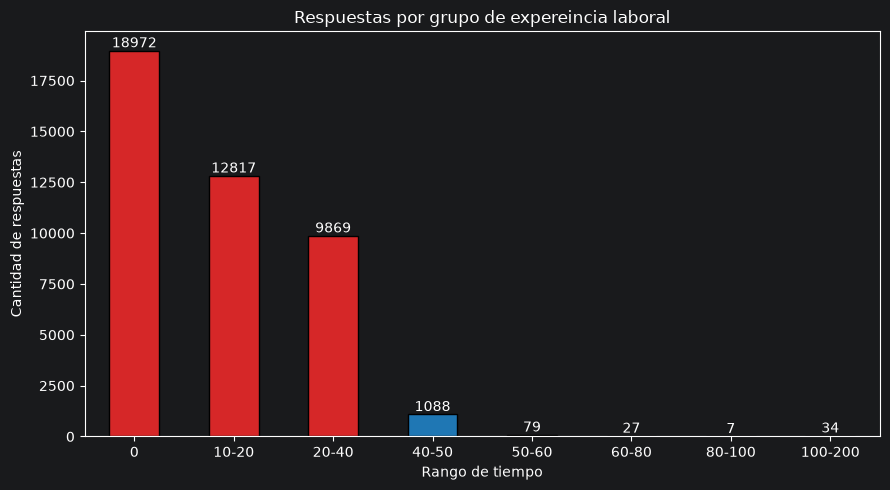

In [115]:
datos=Stack_data["WorkExp"].dropna()
limites = [0, 10, 20, 40, 51, 60,80, 100, 200,]
etiquetas = ["0", "10-20", "20-40", "40-50", "50-60", "60-80","80-100","100-200"]

conteo = pd.cut(datos, bins=limites, labels=etiquetas, right=False).value_counts().sort_index()

colores = ["tab:red" if i < 3 else "tab:blue" for i in range(len(conteo))]  # rojo = por debajo de 10^6

ax = conteo.plot(kind="bar", color=colores, edgecolor="black", figsize=(9, 5))
ax.bar_label(ax.containers[0])
ax.set_title("Respuestas por grupo de expereincia laboral")
ax.set_xlabel("Rango de tiempo")
ax.set_ylabel("Cantidad de respuestas")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Podemos ver que hay valores que no tienen sentido, asi que decidimos recortar los mayores a 50 (seguimos teniendo gran parte de los datos), lo mismo haremos con years code

In [116]:
cols = ['WorkExp', 'YearsCode']
for c in cols:
    Stack_data.loc[Stack_data[c] > 50, c] = np.nan

In [117]:
Stack_data[cols].isna().sum()

WorkExp      6445
YearsCode    6397
dtype: int64

Posibles valores mal cargados

In [118]:
INICIO_TRABAJO = 16
INICIO_CODIGO = 8
lim_work = (Stack_data["Age_max"] - INICIO_TRABAJO).clip(lower=0)
lim_code = (Stack_data["Age_max"] - INICIO_CODIGO).clip(lower=0)

Stack_data["flag_workexp_edad"] = Stack_data["WorkExp"] > lim_work
Stack_data["flag_code_edad"]    = Stack_data["YearsCode"] > lim_code

# Distribución por rango de edad
print(
    Stack_data.groupby("Age")[["flag_workexp_edad", "flag_code_edad"]]
    .agg(["sum"])
)
# Marcar nulos originales y luego anular los que violan el límite
Stack_data["YearsCode_imputed"] = Stack_data["YearsCode"].isna() | Stack_data["flag_code_edad"]
Stack_data["WorkExp_imputed"]   = Stack_data["WorkExp"].isna()   | Stack_data["flag_workexp_edad"]

Stack_data.loc[Stack_data["flag_code_edad"], "YearsCode"] = np.nan
Stack_data.loc[Stack_data["flag_workexp_edad"], "WorkExp"] = np.nan

                  flag_workexp_edad flag_code_edad
                                sum            sum
Age                                               
18-24                            84             20
25-34                            59             15
35-44                            43             34
45-54                            20              8
55-64                             7              0
65+                               0              0
Prefer not to say                 0              0


Si sos nuevo se te imputa 1, si no la mediana de tu grupo etario(no say>media gral)

Para imputar work exp solo podemos asociarlo con la mediana de los grupos que escriben codigo hace tiempo parecido(solo los no imputados) sino la mediana de los grupos etarios y por ultimo la general.

## AIAgents impact & AIAgents Challenge

Decidimos explorar las variables sobre los agentes de IA y notamos esto

In [119]:
prefijos = ("AIAgentImpact","AIAgentChallenge")
cols_guardar = [c for c in Stack_data.columns if c.startswith(prefijos)]

Stack_AI = Stack_data[cols_guardar].copy()

Stack_AI.isna().sum()

AIAgentImpactSomewhat agree           39045
AIAgentImpactNeutral                  39516
AIAgentImpactSomewhat disagree        43400
AIAgentImpactStrongly agree           42504
AIAgentImpactStrongly disagree        45412
AIAgentChallengesNeutral              27896
AIAgentChallengesSomewhat disagree    37066
AIAgentChallengesStrongly agree       26083
AIAgentChallengesSomewhat agree       27244
AIAgentChallengesStrongly disagree    39877
dtype: int64

In [120]:
Stack_AI["AIAgentImpactSomewhat agree"].value_counts()

AIAgentImpactSomewhat agree
AI agents have accelerated my learning about new technologies or codebases.                                                                                                                                                                                                                                              387
AI agents have helped me automate repetitive tasks.                                                                                                                                                                                                                                                                      387
AI agents have reduced the time spent on specific development tasks.                                                                                                                                                                                                                                                     354
AI agents have increa

In [121]:
import re

# Escala 1-5
escala = {"stronglydisagree": 1, "disagree": 2, "neutral": 3,
          "agree": 4, "stronglyagree": 5}

def puntaje_col(col):
    low = re.sub(r"[\s_]", "", col.lower())
    for k in sorted(escala, key=len, reverse=True):   # evita que "disagree" caiga en "agree"
        if k in low:
            return escala[k]
    return None

items_impact = {
    "increased my productivity":        "Impact_Productivity",
    "automate repetitive tasks":        "Impact_AutomateTasks",
    "improved the quality of my code":  "Impact_CodeQuality",
    "accelerated my learning":          "Impact_Learning",
    "solve complex problems":           "Impact_ComplexProblems",
    "reduced the time spent":           "Impact_TimeSaved",
    "improved collaboration":           "Impact_Collaboration",
}
items_challenges = {
    "accuracy of the information":      "Challenge_Accuracy",
    "Integrating AI agents":            "Challenge_Integration",
    "significant time and effort":      "Challenge_LearningCurve",
    "cost of using":                    "Challenge_Cost",
    "security and privacy":             "Challenge_SecurityPrivacy",
    "IT and/or InfoSec":                "Challenge_CompanyPolicy",
}

def construir(df, prefijo, items):
    out = pd.DataFrame(np.nan, index=df.index, columns=list(items.values()))
    for col in [c for c in df.columns if c.startswith(prefijo)]:
        p = puntaje_col(col)
        if p is None:
            print(f"⚠ Sin categoría detectada: {col}")
            continue
        for patron, nombre in items.items():
            out.loc[df[col].str.contains(patron, case=False, na=False), nombre] = p
    return out

Stack_AI_num = pd.concat([
    construir(Stack_AI, "AIAgentImpact", items_impact),
    construir(Stack_AI, "AIAgentChallenge", items_challenges),
], axis=1)

# Promedios por fila (ignora NaN automáticamente)
cols_impact = list(items_impact.values())
cols_challenges = list(items_challenges.values())

Stack_AI_num["avgAIimpact"] = Stack_AI_num[cols_impact].mean(axis=1)
Stack_AI_num["avgAIchallenge"] = Stack_AI_num[cols_challenges].mean(axis=1)
Stack_AI[["avgAIimpact", "avgAIchallenge"]] = Stack_AI_num[["avgAIimpact", "avgAIchallenge"]]
# Verificación
print(Stack_AI_num[["avgAIimpact", "avgAIchallenge"]].describe())
print(Stack_AI_num[["avgAIimpact", "avgAIchallenge"]].isna().sum())

        avgAIimpact  avgAIchallenge
count  12831.000000    28932.000000
mean       3.429941        3.632949
std        0.877685        0.648516
min        1.000000        1.000000
25%        3.000000        3.166667
50%        3.428571        3.666667
75%        4.000000        4.000000
max        5.000000        5.000000
avgAIimpact       36360
avgAIchallenge    20259
dtype: int64


Son variables que con un poco de trabajo podriamos llevar a continuas entonces lo hacemos

In [122]:
# Debería dar 0 conflictos
conteo = sum(Stack_AI[c].str.contains("increased my productivity", case=False, na=False).astype(int)
             for c in Stack_AI.columns if c.startswith("AIAgentImpact"))
print((conteo > 1).sum())

0


In [123]:
nuevas = Stack_AI_num[["avgAIimpact", "avgAIchallenge"]]
Stack_data=Stack_data.join(nuevas)

## OPSYS PERSONAL

Primero nos encargamos de separar los valores almacenados en la variable

In [124]:
opsys_limpio = Stack_data['OpSysPersonal use'].dropna()
opsys_menciones = (
    opsys_limpio.astype(str)
    .str.split(';')
    .explode()
    .str.strip()
)

opsys_menciones = opsys_menciones[opsys_menciones != '']
print("\nFrecuencias crudas observadas por opción:")
print(opsys_menciones.value_counts())



Frecuencias crudas observadas por opción:
OpSysPersonal use
Windows                              17925
MacOS                                10350
Android                               9201
Ubuntu                                8784
iOS                                   5963
Linux (non-WSL)                       5561
Windows Subsystem for Linux (WSL)     5024
Debian                                3599
Arch                                  3070
iPadOS                                2554
Fedora                                1825
NixOS                                 1065
Pop!_OS                                739
ChromeOS                               710
Red Hat                                565
Name: count, dtype: int64


Luego agrupamos las distros de linux en un solo grupo(tambien con mac y android respectivamente)

In [125]:
def agrupar_sistema(nombre):
    distros_linux = [
        'ubuntu', 'debian', 'fedora', 'arch', 'red hat',
        'nixos', 'pop!_os', 'linux (non-wsl)'
    ]
    nombre_lower = str(nombre).lower().strip()

    if any(distro in nombre_lower for distro in distros_linux):
        return 'Linux / GNU'
    elif 'windows subsystem for linux' in nombre_lower or 'wsl' in nombre_lower:
        return 'WSL'
    elif 'windows' in nombre_lower:
        return 'Windows'
    elif any(apple in nombre_lower for apple in ['macos', 'ios', 'ipados']):
        return 'macOS / Apple'
    elif any(movil in nombre_lower for movil in ['android', 'chromeos']):
        return 'Móvil / Otros'
    else:
        return 'Otros'

opsys_agrupado = opsys_menciones.apply(agrupar_sistema)
tabla_opsys = pd.DataFrame({
    'Frecuencia Absoluta (fi)': opsys_agrupado.value_counts(),
    'Frecuencia Relativa (hi)': opsys_agrupado.value_counts(normalize=True),
    'Porcentaje (%)': opsys_agrupado.value_counts(normalize=True) * 100
})

print("--- Tabla de Frecuencias de Sistemas Operativos Agrupados ---")
print(tabla_opsys.round(2))
moda_opsys = opsys_agrupado.mode()
print(f"\nModa univariada: {moda_opsys}")


--- Tabla de Frecuencias de Sistemas Operativos Agrupados ---
                   Frecuencia Absoluta (fi)  Frecuencia Relativa (hi)  \
OpSysPersonal use                                                       
Linux / GNU                           25208                      0.33   
macOS / Apple                         18867                      0.25   
Windows                               17925                      0.23   
Móvil / Otros                          9911                      0.13   
WSL                                    5024                      0.07   

                   Porcentaje (%)  
OpSysPersonal use                  
Linux / GNU                 32.77  
macOS / Apple               24.52  
Windows                     23.30  
Móvil / Otros               12.88  
WSL                          6.53  

Moda univariada: 0    Linux / GNU
Name: OpSysPersonal use, dtype: str


## NewRole

In [126]:
Stack_apartadas["NewRole"].value_counts()

NewRole
I have neither consider or transitioned into a new career or industry          16205
I have somewhat considered changing my career and/or the industry I work in    10233
I have strongly considered changing my career and/or the industry I work in     5253
I have transitioned into a new career and/or industry voluntarily               3111
I have transitioned into a new career and/or industry involuntarily              725
Name: count, dtype: int64

Esta variable se trabaja de una manera particular para abordar la ultima hipotesis, para evitar la perdida de informacion las modificaciones se hacen sobre esa seccion (H6)

## JobSatPoints

JobSatPoints refiere a en que altura de un ranking se encuentran distintos aspectos del ambito laboral. Con ayuda del sitio de Kaggle mapeamos esto:

In [127]:
mapa_jobsat = {
    "JobSatPoints_1": "JS_QualityControl",
    "JobSatPoints_2": "JS_Autonomy",
    "JobSatPoints_16": "JS_LikeManager",
    "JobSatPoints_3": "JS_TeamSupport",
    "JobSatPoints_4": "JS_ExpertMentors",
    "JobSatPoints_5": "JS_MentorJuniors",
    "JobSatPoints_6": "JS_SpecializedExpertise",
    "JobSatPoints_7": "JS_RealWorldProblems",
    "JobSatPoints_8": "JS_StabilityGrowth",
    "JobSatPoints_9": "JS_ChallengingInnovation",
    "JobSatPoints_10": "JS_NewTech",
    "JobSatPoints_11": "JS_PayBenefits",
    "JobSatPoints_13": "JS_PeerRecognition",
    "JobSatPoints_14": "JS_LeaderRecognition",
    "JobSatPoints_15": "JS_Other",
    "JobSatPoints_15_TEXT": "JS_Other_Text",
}

Stack_apartadas = Stack_apartadas.rename(columns=mapa_jobsat)

# Verificación: columnas JobSatPoints que quedaron sin renombrar
print([c for c in Stack_apartadas.columns if c.startswith("JobSatPoints")])

[]


In [128]:
Stack_apartadas["JS_Other"].value_counts()

JS_Other
15.0    23980
1.0       297
14.0      200
2.0        91
13.0       87
12.0       53
3.0        43
11.0       38
4.0        30
9.0        28
5.0        25
10.0       20
8.0        19
7.0        16
6.0        16
Name: count, dtype: int64

In [129]:
Stack_apartadas["JS_Other_Text"].value_counts().sum()

np.int64(664)

Como son menos del 3% de los datos se decide quitarlos porque el trajo para recuperarlos supone problemas de representacion en la interpretacion de los datos que estamos tomando. Luego se decide recodificar el ranking del 1 al 5 agrupando de la siguiente manera

In [130]:
cols_js = [c for c in Stack_apartadas.columns
           if c.startswith("JS_") and c != "JS_Other_Text" and c != "JS_Other"]

recodificar = {
    1: 5, 2: 5, 3: 5,
    4: 4, 5: 4, 6: 4,
    7: 3, 8: 3, 9: 3,
    10: 2, 11: 2, 12: 2,
    13: 1, 14: 1, 15: 1,
}

if Stack_apartadas[cols_js].max().max() <= 5:
    print("Parece que las columnas ya fueron recodificadas (máx <= 5).")
else:
    Stack_apartadas[cols_js] = (
        Stack_apartadas[cols_js]
        .apply(pd.to_numeric, errors="coerce")
        .apply(lambda col: col.map(recodificar))
    )

## Remote Work

Se Renombra

In [131]:
Stack_data["RemoteWork"].value_counts()

RemoteWork
Remote                                                                          10931
Hybrid (some remote, leans heavy to in-person)                                   6732
In-person                                                                        6042
Hybrid (some in-person, leans heavy to flexibility)                              5831
Your choice (very flexible, you can come in when you want or just as needed)     4244
Name: count, dtype: int64

In [132]:
Stack_data["RemoteWork"] = Stack_data["RemoteWork"].replace({
    "Hybrid (some remote, leans heavy to in-person)": "Híbrido (predomina presencial)",
    "Hybrid (some in-person, leans heavy to flexibility)": "Híbrido (flexible)",
    "Remote": "Remoto",
    "In-person": "Presencial",
    "Your choice (very flexible, you can come in when you want or just as needed)": "A eleccion del empleado",
})

## JobSat

In [133]:
Stack_data["JobSat"].isna().sum()

np.int64(22521)

Mucho para imputar(no se hace)

## Industry

In [134]:
Stack_data["Industry"].value_counts()

Industry
Software Development                          16282
Other:                                         2667
Internet, Telecomm or Information Services     1698
Fintech                                        1690
Banking/Financial Services                     1437
Healthcare                                     1397
Manufacturing                                  1315
Government                                     1183
Higher Education                               1167
Retail and Consumer Services                   1053
Transportation, or Supply Chain                 910
Computer Systems Design and Services            894
Media & Advertising Services                    773
Energy                                          742
Insurance                                       434
Name: count, dtype: int64

A pesar de que son varias opciones hacemos one-hot

In [135]:
Stack_data["Industry"] = Stack_data["Industry"].replace("Other", np.nan)
ind_dummies = pd.get_dummies(Stack_data["Industry"], prefix="Ind", dtype=int)
Stack_data = pd.concat([Stack_data.drop(columns=ind_dummies.columns, errors="ignore"), ind_dummies], axis=1)

# Analisis Exploratorio

## Cruzar variables con edad

Heatmap

In [136]:
def heatmap(tabla, xlabel, titulo, size=(10, 4), rot=0):
    plt.figure(figsize=size)
    sns.heatmap(tabla, annot=True, fmt=".0%", cmap="Blues")
    plt.xlabel(xlabel)
    plt.ylabel("Rango de edad")
    plt.title(titulo)
    plt.xticks(rotation=rot, ha="right" if rot else "center")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


orden_age = list(renombrar_age.values())   # ["18-24", "25-34", ...]
orden_org = list(renombrar_org.values())   # ["Freelance", "<20", ...]


Edad y Org

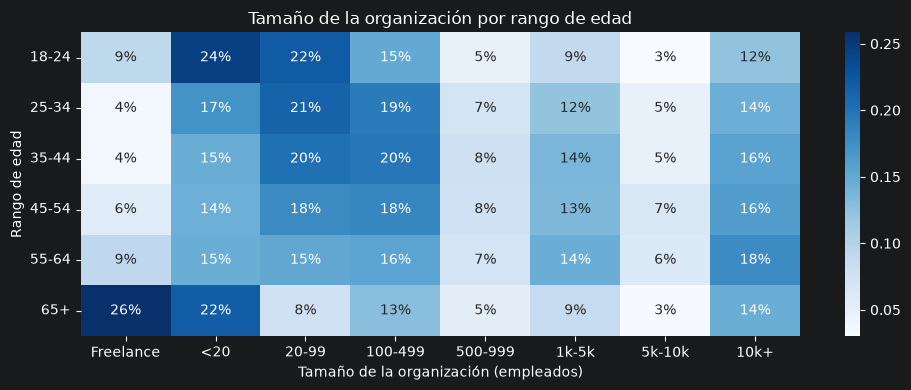

In [137]:
datos = Stack_data[Stack_data["Age"].isin(orden_age) & Stack_data["OrgSize"].isin(orden_org)]
tabla = (pd.crosstab(datos["Age"], datos["OrgSize"], normalize="index")
           .reindex(index=orden_age, columns=orden_org, fill_value=0))
heatmap(tabla, "Tamaño de la organización (empleados)", "Tamaño de la organización por rango de edad")

Edad y Trabajo

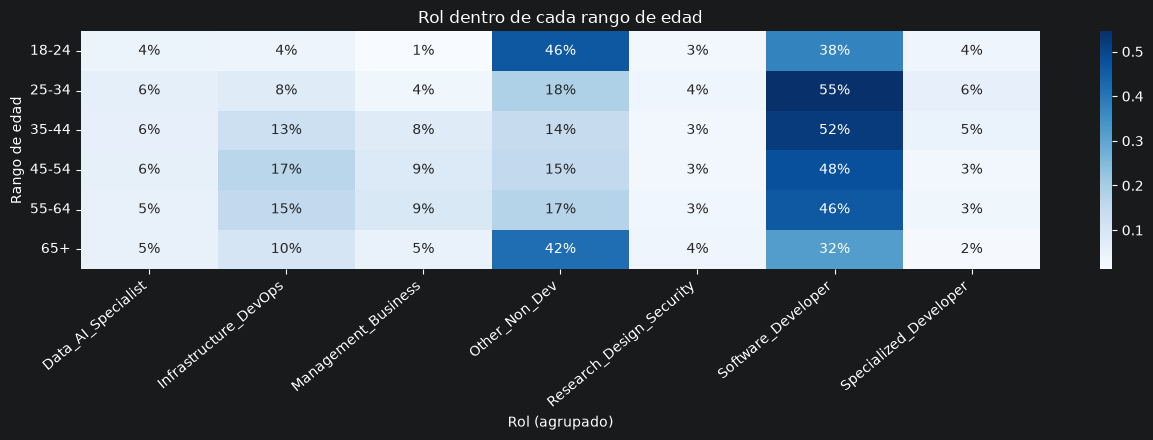

In [138]:
datos = Stack_data[Stack_data["Age"].isin(orden_age)]
share = (pd.crosstab(datos["Age"], datos["DevType_Grouped"], normalize="index")
           .reindex(orden_age))
heatmap(share, "Rol (agrupado)", "Rol dentro de cada rango de edad", size=(13, 4.5), rot=40)

## AI opinion

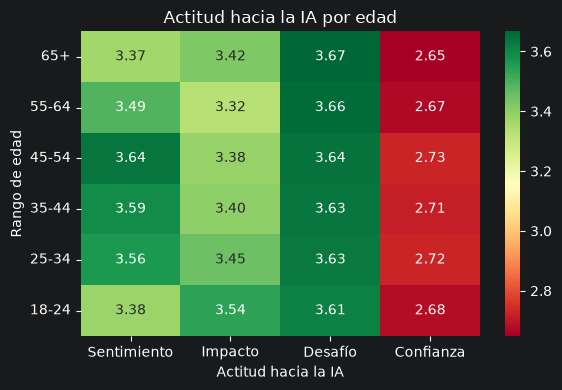

In [139]:
ai_num = ["AISent_num", "avgAIimpact", "avgAIchallenge", "AIAcc_num"]

# Nombres cortos solo para graficar (el dataset no cambia)
renombrar_ai = {
    "AISent_num": "Sentimiento",
    "avgAIimpact": "Impacto",
    "avgAIchallenge": "Desafío",
    "AIAcc_num": "Confianza",
}
orden_age_inv = orden_age[::-1]   # ["65+", "55-64", ..., "18-24"]

# 3a. Promedio de cada actitud por edad
medias = Stack_data.groupby("Age")[ai_num].mean().reindex(orden_age_inv).rename(columns=renombrar_ai)

plt.figure(figsize=(6, 4))
sns.heatmap(medias, annot=True, fmt=".2f", cmap="RdYlGn")
plt.xlabel("Actitud hacia la IA")
plt.ylabel("Rango de edad")
plt.title("Actitud hacia la IA por edad")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Veamos porque la confianza dio tan baja

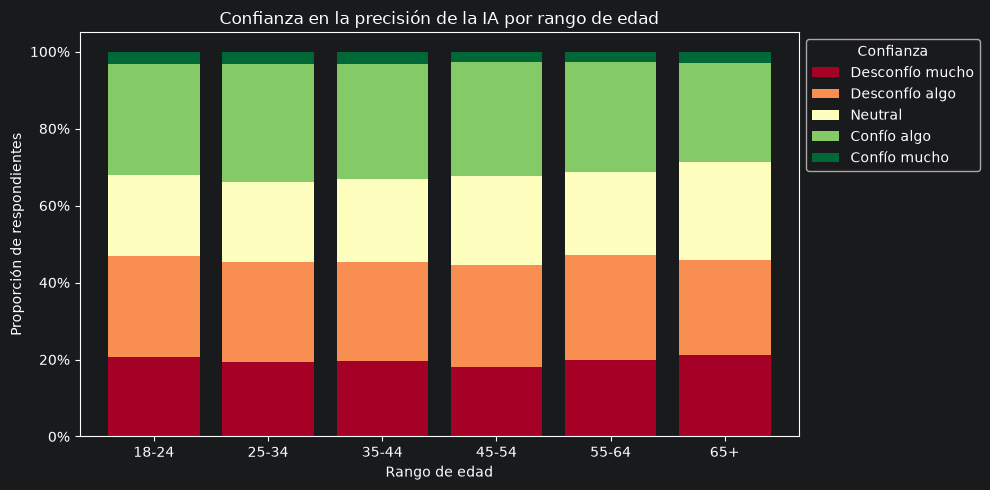

In [140]:
orden_conf = ["Highly distrust", "Somewhat distrust", "Neither trust nor distrust",
              "Somewhat trust", "Highly trust"]
etiquetas_conf = ["Desconfío mucho", "Desconfío algo", "Neutral", "Confío algo", "Confío mucho"]

datos = Stack_data[Stack_data["AIAcc"].isin(orden_conf)]
dist = (pd.crosstab(datos["Age"], datos["AIAcc"], normalize="index")
          .reindex(index=orden_age, columns=orden_conf))
dist.columns = etiquetas_conf

ax = dist.plot(kind="bar", stacked=True, figsize=(10, 5), colormap="RdYlGn", width=0.8)
ax.set_title("Confianza en la precisión de la IA por rango de edad")
ax.set_xlabel("Rango de edad")
ax.set_ylabel("Proporción de respondientes")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.xticks(rotation=0)
plt.legend(title="Confianza", bbox_to_anchor=(1, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Correlacion

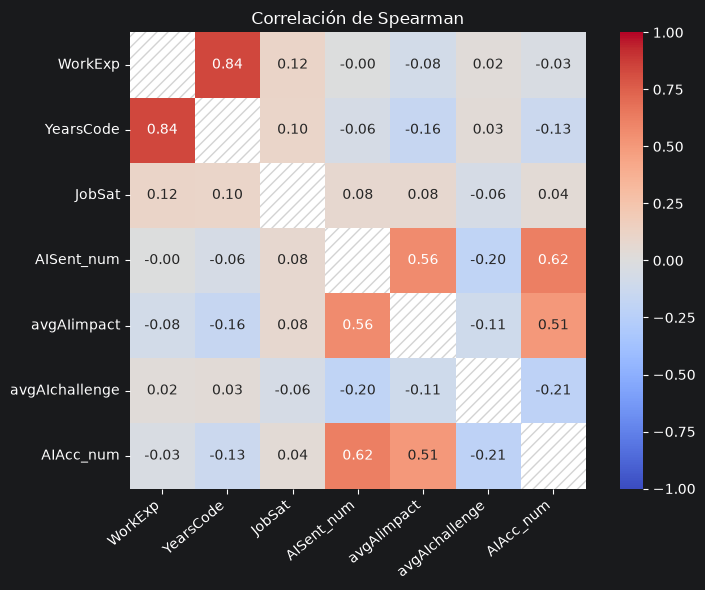

In [141]:
num_cols = ["WorkExp", "YearsCode", "JobSat"] + ai_num   # ajustá

corr = Stack_data[num_cols].corr(method="spearman")
mask = np.eye(len(corr), dtype=bool)   # True solo en la diagonal

plt.figure(figsize=(8, 6))
ax = sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
                 vmin=-1, vmax=1, square=True)
ax.set_facecolor("white")          # las celdas enmascaradas se ven grises
for i in range(len(corr)):
    ax.add_patch(Rectangle((i, i), 1, 1, fill=False, hatch="///",
                           edgecolor="lightgrey", linewidth=0))
plt.title("Correlación de Spearman")
plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# HIPÓTESIS 1

Con las frecuencias y porcentajes calculados mostramos graficamente para ver si se cumple nuestra hipotesis

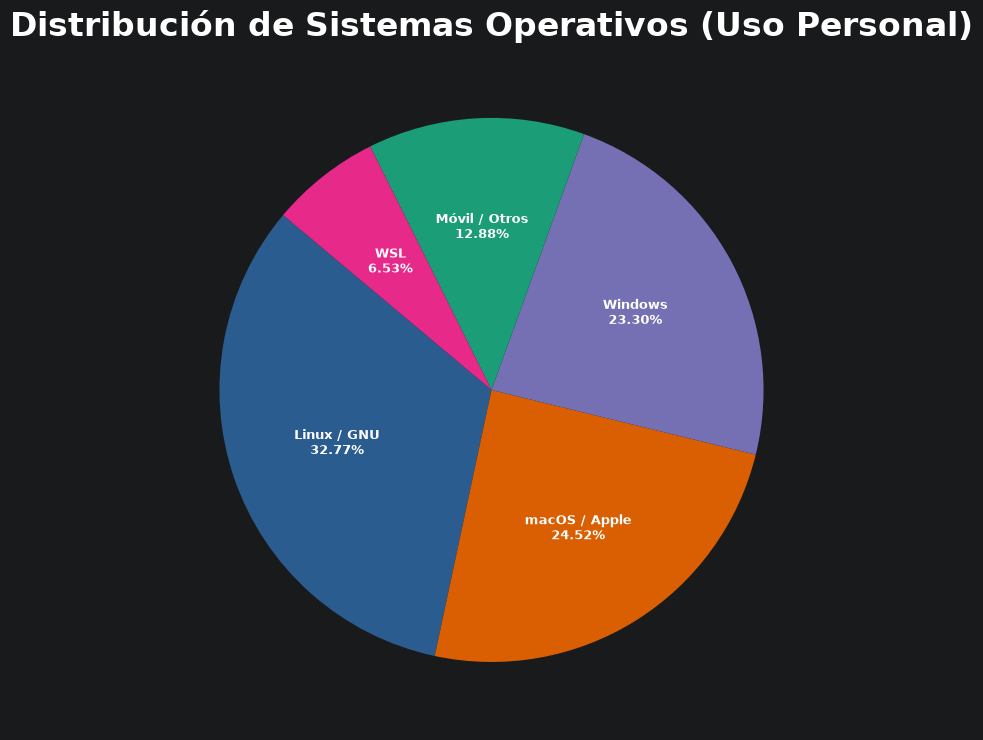

In [142]:
categorias = tabla_opsys.index
porcentajes = tabla_opsys['Porcentaje (%)'].values
etiquetas_internas = [
    f'{cat}\n{pct:.2f}%' for cat, pct in zip(categorias, porcentajes)
]

colores = ['#2b5c8f', '#d95f02', '#7570b3', '#1b9e77', '#e7298a']
fig, ax = plt.subplots(figsize=(7.5, 7.5))

wedges, texts = ax.pie(
    porcentajes,
    labels=etiquetas_internas,
    labeldistance=0.6,
    startangle=140,
    colors=colores,
    textprops=dict(
        fontsize=9, color='white', weight='bold', ha='center', va='center'
    ),
)
ax.set_title(
    'Distribución de Sistemas Operativos (Uso Personal)',
    fontsize=24,
    pad=10,
    fontweight='bold',
)

plt.tight_layout()
plt.show()


Podemos ver que el mercado tiene una distribucion bastante pareja, que no tiende al software libre tan abruptamente

# HIPÓTESIS 2

In [143]:
d = Stack_data[['JobSat','RemoteWork']].dropna()

In [144]:
agrupar_por_modalidad = d.groupby('RemoteWork')['JobSat'].agg(["count", "mean", "median", "std"])
agrupar_por_modalidad

,count,mean,median,std
RemoteWork,,,,
A eleccion del empleado,2848,7.426966,8.0,1.831582
Híbrido (flexible),4046,7.207365,8.0,1.828292
Híbrido (predomina presencial),4499,7.082240,7.0,1.885540
Presencial,3496,6.988272,7.0,2.045583
Remoto,7908,7.323849,8.0,1.970300


In [145]:
grupos = [g["JobSat"].values for _, g in d.groupby("RemoteWork")]

# Normalidad (se estandariza porque kstest contra 'norm' asume media 0 y desvío 1)
z = (d["JobSat"] - d["JobSat"].mean()) / d["JobSat"].std()
ks = stats.kstest(z, "norm")
print(f"Kolmogorov-Smirnov (JobSat): D = {ks.statistic:.3f}, p = {ks.pvalue:.4f}")

# Homocedasticidad
lev = stats.levene(*grupos, center="median")
print(f"Levene: estadístico = {lev.statistic:.3f}, p = {lev.pvalue:.4f}")

Kolmogorov-Smirnov (JobSat): D = 0.175, p = 0.0000
Levene: estadístico = 12.212, p = 0.0000


In [146]:
H, p_kw = stats.kruskal(*grupos)

n, k, alpha = len(d), len(grupos), 0.05
print(f"Kruskal-Wallis: H = {H:.2f}, p = {p_kw:.4g}")
print(f"n = {n}, grupos = {k}")

if p_kw < alpha:
    print(f"Diferencias significativas (p < {alpha}): JobSat difiere entre las modalidades de RemoteWork.")
else:
    print(f"Diferencias NO significativas (p >= {alpha}): no hay evidencia de que JobSat difiera entre las modalidades de RemoteWork.")

Kruskal-Wallis: H = 150.48, p = 1.609e-31
n = 22797, grupos = 5
Diferencias significativas (p < 0.05): JobSat difiere entre las modalidades de RemoteWork.


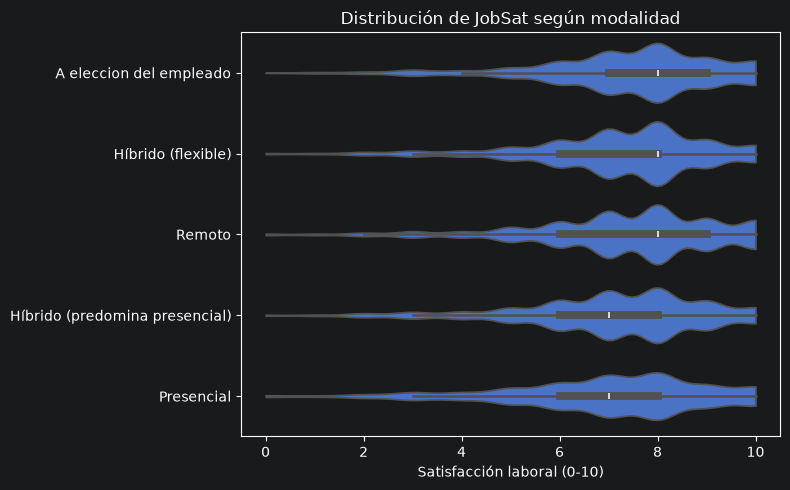

In [147]:
orden = d.groupby("RemoteWork")["JobSat"].median().sort_values(ascending=False).index

plt.figure(figsize=(8, 5))
sns.violinplot(data=d, y="RemoteWork", x="JobSat", order=orden,
               inner="box", cut=0, orient="h")
plt.title("Distribución de JobSat según modalidad")
plt.xlabel("Satisfacción laboral (0-10)")
plt.ylabel("")
plt.tight_layout()
plt.show()

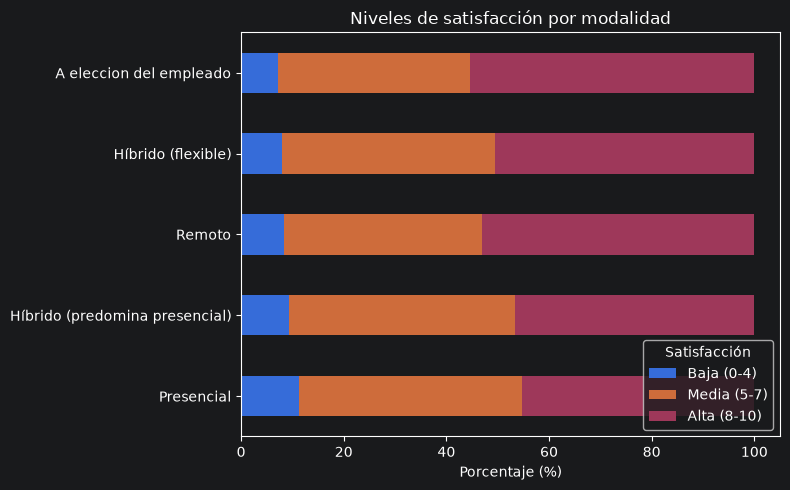

In [148]:
orden = d.groupby("RemoteWork")["JobSat"].median().sort_values(ascending=False).index

d["JobSat_cat"] = pd.cut(d["JobSat"], bins=[-1, 4, 7, 10],
                         labels=["Baja (0-4)", "Media (5-7)", "Alta (8-10)"])
prop = pd.crosstab(d["RemoteWork"], d["JobSat_cat"], normalize="index").loc[orden][::-1] * 100

ax = prop.plot(kind="barh", stacked=True, figsize=(8, 5))
ax.set_title("Niveles de satisfacción por modalidad")
ax.set_xlabel("Porcentaje (%)")
ax.set_ylabel("")
ax.legend(title="Satisfacción", loc="lower right")
plt.tight_layout()
plt.show()

# HIPÓTESIS 3

Se toma solo las tuplas que tienen informacion (los agentes quitan la mayoria)

In [149]:
vars_data = ["AISent_num", "AIAcc_num","JobSat","WorkExp","org_size_ordinal"]
Stack_AI_Reg = pd.concat(
    [Stack_AI_num[["avgAIimpact", "avgAIchallenge"]], Stack_data[vars_data]],
    axis=1
)

print("Filas iniciales:", len(Stack_AI_Reg))
Stack_AI_Reg = Stack_AI_Reg.dropna()
print("Filas finales:", len(Stack_AI_Reg))

Filas iniciales: 49191
Filas finales: 7872


In [150]:
y_col = "avgAIimpact"
X_cols = [c for c in Stack_AI_Reg.columns if c != y_col]

Z = pd.DataFrame(
    StandardScaler().fit_transform(Stack_AI_Reg),
    columns=Stack_AI_Reg.columns, index=Stack_AI_Reg.index
)

X = sm.add_constant(Z[X_cols])
model = sm.OLS(Z[y_col], X).fit(cov_type="HC3")
print(model.summary())
res = pd.DataFrame({
    "beta_std": model.params,
    "IC95_inf": model.conf_int()[0],
    "IC95_sup": model.conf_int()[1],
    "p_valor": model.pvalues,
}).drop("const").round(3)
vif = pd.Series(
    [variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
    index=X_cols
).round(2)
print(vif)

                            OLS Regression Results                            
Dep. Variable:            avgAIimpact   R-squared:                       0.417
Model:                            OLS   Adj. R-squared:                  0.417
Method:                 Least Squares   F-statistic:                     877.7
Date:                Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:13:21   Log-Likelihood:                -9045.8
No. Observations:                7872   AIC:                         1.811e+04
Df Residuals:                    7865   BIC:                         1.815e+04
Df Model:                           6                                         
Covariance Type:                  HC3                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const             1.839e-16      0.009  

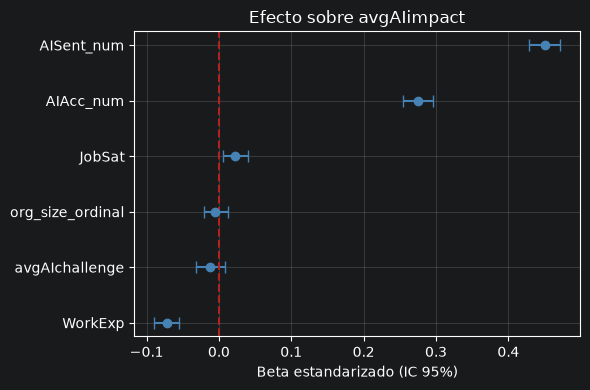

In [151]:
r = res.sort_values("beta_std")
fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(r["beta_std"], range(len(r)),
            xerr=[r["beta_std"] - r["IC95_inf"], r["IC95_sup"] - r["beta_std"]],
            fmt="o", color="steelblue", capsize=4)
ax.axvline(0, color="firebrick", ls="--")
ax.set_yticks(range(len(r)))
ax.set_yticklabels(r.index)
ax.set_xlabel("Beta estandarizado (IC 95%)")
ax.set_title(f"Efecto sobre {y_col}")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Como vemos lo que mas se asocia a un alto impacto son AISent y AIAcc

Rehacemos el modelo para ver si es mejor sin las variables ruido

In [152]:
vars_data = ["AISent_num", "AIAcc_num", "JobSat", "WorkExp"]
Stack_AI_Reg = pd.concat(
    [Stack_AI_num[["avgAIimpact"]], Stack_data[vars_data]],
    axis=1
)

print("Filas iniciales:", len(Stack_AI_Reg))
Stack_AI_Reg = Stack_AI_Reg.dropna()
print("Filas finales:", len(Stack_AI_Reg))

Filas iniciales: 49191
Filas finales: 9485


In [153]:
y_col = "avgAIimpact"
X_cols = [c for c in Stack_AI_Reg.columns if c != y_col]

Z = pd.DataFrame(
    StandardScaler().fit_transform(Stack_AI_Reg),
    columns=Stack_AI_Reg.columns, index=Stack_AI_Reg.index
)

X = sm.add_constant(Z[X_cols])
model = sm.OLS(Z[y_col], X).fit(cov_type="HC3")
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            avgAIimpact   R-squared:                       0.403
Model:                            OLS   Adj. R-squared:                  0.403
Method:                 Least Squares   F-statistic:                     1448.
Date:                Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:13:22   Log-Likelihood:                -11012.
No. Observations:                9485   AIC:                         2.203e+04
Df Residuals:                    9480   BIC:                         2.207e+04
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const      -6.989e-17      0.008   -8.8e-15      1.0

No es el mejor modelo pero descarta la supocicion que teniamos sobre orgSize y un poco la de jobSat

# HIPOTESIS 4

Primero podemos ver que que el grupo de obvservaciones de Argentina registro el salario en distintos formatos

In [154]:
arg = Stack_data[Stack_data["Country"] == "Argentina"]
arg["Currency"].value_counts()


Currency
ARS\tArgentine peso         142
USD United States dollar     80
Name: count, dtype: int64

In [155]:
tasa_usd = 1570 #(11/05/2026)
arg["moneda_cod"] = arg["Currency"].str[:3]

arg["comp_ars"] = arg["CompTotal"].where(arg["moneda_cod"] == "ARS", arg["CompTotal"] * tasa_usd)

Con un histograma podemos ver como se distribuyen esos valores para buscar valores sospechosos

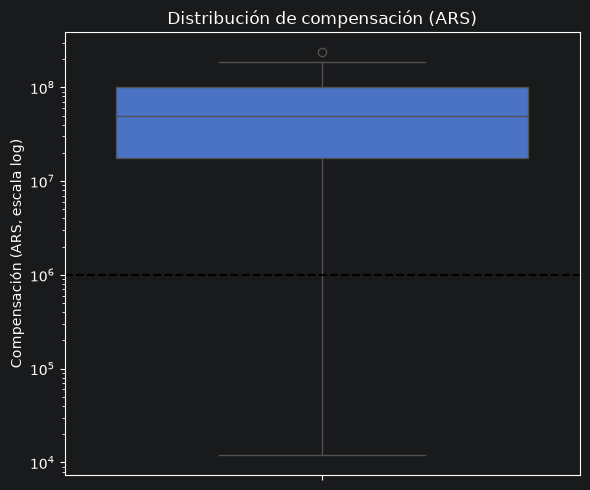

In [156]:
datos = arg["comp_ars"].dropna()
datos = datos[datos > 0]

plt.figure(figsize=(6, 5))
ax = sns.boxplot(y=datos)
ax.axhline(1e6, color="black", linestyle="--")
ax.set_yscale("log")
ax.set_title("Distribución de compensación (ARS)")
ax.set_ylabel("Compensación (ARS, escala log)")
plt.tight_layout()
plt.show()

Como vemos hay valores que son sospechosos, el monto deberia ser anual y es raro que cobres menos de 1.000.000 de pesos anualmente, tambien miramos los valores altos para ver si algun outlier nos parece exesivo (300.000.000 anual son 200.000 dolares)

In [157]:
mostrar = (arg["comp_ars"] < 1e6) | (arg["comp_ars"] > 3e8)
sospechosos = arg[mostrar].copy()
sospechosos[["Currency", "comp_ars","WorkExp","Employment"]].sort_values("comp_ars").head(20)

,Currency,comp_ars,WorkExp,Employment
1301,USD United States dollar,0.0,14.0,Not employed
10240,ARS\tArgentine peso,0.0,NaN,Student
34208,ARS\tArgentine peso,0.0,NaN,Not employed
40799,ARS\tArgentine peso,0.0,8.0,Not employed
25963,ARS\tArgentine peso,12000.0,NaN,Employed
17847,ARS\tArgentine peso,14000.0,20.0,"Independent contractor, freelancer, or self-em..."
23274,ARS\tArgentine peso,15000.0,5.0,Employed
32101,ARS\tArgentine peso,24000.0,4.0,Employed
12034,ARS\tArgentine peso,38000.0,3.0,Employed
5661,ARS\tArgentine peso,40000.0,18.0,Employed


Como vemos todos los valores particulares son los valores bajos, aun asi decidimos eliminar solo los valores <0 para darle exigencia al test, considerando que parece que se va a cumplir por la distribucion de los datos

In [158]:
arg["comp_ars"] = arg["comp_ars"].fillna(0)
mask_eliminar = (arg["comp_ars"] <= 0)
arg=arg[~mask_eliminar].copy()
arg["comp_ars"].isna().sum()

np.int64(0)

Con los datos limpios se verifica la normalidad y se calculan estadisticos para ver si es necesario aplicar algun otro test

n = 160 | media = 65,096,313 | mediana = 50,000,000 | umbral = 14344200

Shapiro-Wilk: W = 0.9129, p = 3.452e-08


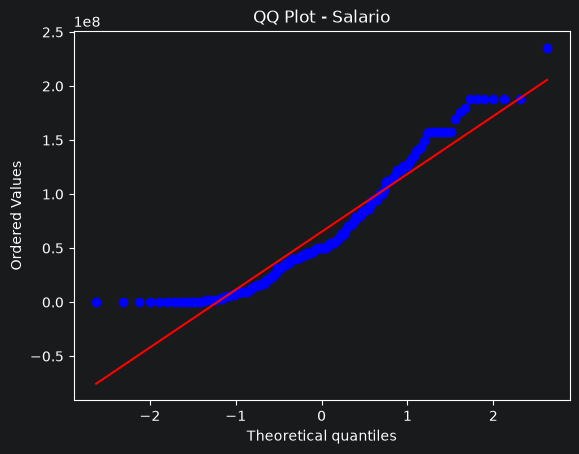

In [159]:
# PARÁMETROS
SMVM_MENSUAL = 367800         #Se elije por el SMVM de JUNIO de 2026 (Exigente)
MULTIPLO = 3
ALFA = 0.05
x=arg["comp_ars"]
umbral = MULTIPLO * SMVM_MENSUAL*13 # Se multiplica por 13 por que es anual + aguinaldo (el peor de los casos)
print(f"n = {len(x)} | media = {x.mean():,.0f} | mediana = {x.median():,.0f} | umbral = {umbral}")
w, p_sw = stats.shapiro(x)
print(f"\nShapiro-Wilk: W = {w:.4f}, p = {p_sw:.4g}")

stats.probplot(x, dist="norm", plot=plt)
plt.title("QQ Plot - Salario")
plt.show()

Como vemos, la media y la mediana superan ampliamente el umbral evaluado de manera exigente asi que podemos decir que los desarrolladores ganan mas de 3 salarios minimos. Como los datos no son normales el test que podria correrse no es parametrico lo cual lo hace menos podersoso y no captara ninguna diferencia con lo que podemos cocnluir con la informacion de los estadisticos calculados

# HIPÓTESIS 5

Antes de pasar con la hipotesis nos gustaria ver si podemos sacar alguna conclusion con algun box plot, no conviene usar un gragfico de dipersion porque no puede apreciarse bien dado que una variable es una categorica ordinal adaptada a discreta

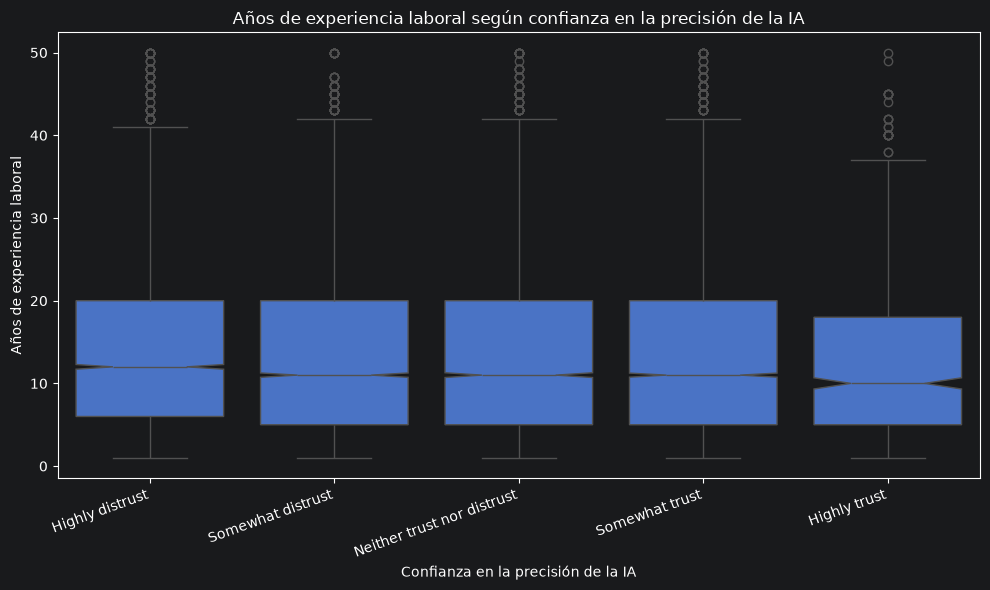

In [160]:
orden = [
    "Highly distrust",
    "Somewhat distrust",
    "Neither trust nor distrust",
    "Somewhat trust",
    "Highly trust",
]

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=Stack_data, x="AIAcc", y="WorkExp", order=orden, ax=ax,notch= True)
ax.set_title("Años de experiencia laboral según confianza en la precisión de la IA")
ax.set_xlabel("Confianza en la precisión de la IA")
ax.set_ylabel("Años de experiencia laboral")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

Pareciera ser bastente pareja la distribucion con una muy leve diferencia a favor de la hipotesis en los extremos, Aprovechando la transformacion corremos tests de correlacion para ver si hay algun tipo de correlacion entre las variables

In [161]:
datos = Stack_data[["AIAcc_num", "WorkExp"]].dropna()

# Pearson
r, p = stats.pearsonr(datos["AIAcc_num"], datos["WorkExp"])
print(f"Pearson: r = {r:.3f}, p = {p:.4f}")

# Spearman
rho, p_s = stats.spearmanr(datos["AIAcc_num"], datos["WorkExp"])
print(f"Spearman: rho = {rho:.3f}, p = {p_s:.4f}")
print(f"n = {len(datos)}")

Pearson: r = -0.036, p = 0.0000
Spearman: rho = -0.034, p = 0.0000
n = 30554


Como vemos, la correlacion es practicamente nula, pero vamos a comprobar si las diferencias son significativas

In [162]:
datos = Stack_data[["AIAcc_num", "WorkExp"]].dropna()

ks_aia = stats.kstest(datos["AIAcc_num"], 'norm')
ks_work = stats.kstest(datos["WorkExp"], 'norm')

print(f"Kolmogorov-Smirnov (AIAcc_num): D = {ks_aia.statistic:.3f}, p = {ks_aia.pvalue:.4f}")
print(f"Kolmogorov-Smirnov (WorkExp): D = {ks_work.statistic:.3f}, p = {ks_work.pvalue:.4f}")

grupos_workexp = [grupo["WorkExp"].values for _, grupo in datos.groupby("AIAcc_num")]
stat_levene, p_levene = stats.levene(*grupos_workexp)
print(f"Levene (Homocedasticidad): estadístico = {stat_levene:.3f}, p = {p_levene:.4f}")

Kolmogorov-Smirnov (AIAcc_num): D = 0.841, p = 0.0000
Kolmogorov-Smirnov (WorkExp): D = 0.929, p = 0.0000
Levene (Homocedasticidad): estadístico = 6.642, p = 0.0000


Kruskal-Wallis es lo unico que podemos usar en este caso

In [163]:
datos = Stack_data[["AIAcc_num", "WorkExp"]].dropna()

grupos = [g["WorkExp"].values for _, g in datos.groupby("AIAcc_num")]
H, p_kw = stats.kruskal(*grupos)

n = len(datos)
k = len(grupos)
alpha = 0.05

print(f"Kruskal-Wallis: H = {H:.2f}, p = {p_kw:.4g}")
print(f"n = {n}, grupos = {k}")

if p_kw < alpha:
    print(f"Diferencias significativas (p < {alpha}): WorkExp difiere entre los niveles de AIAcc_num.")
else:
    print(f"Diferencias NO significativas (p >= {alpha}): no hay evidencia de que WorkExp difiera entre los niveles de AIAcc_num.")

Kruskal-Wallis: H = 41.73, p = 1.901e-08
n = 30554, grupos = 5
Diferencias significativas (p < 0.05): WorkExp difiere entre los niveles de AIAcc_num.


Vemos que son significativas, asi que aunque poco la Experiencia laboral influye inversamente en la confianza a la IA

# HIPÓTESIS 6

Eliminar las muestras de NewRole que empiezan con "I have transitioned"

In [164]:
Stack_apartadas = Stack_apartadas[
    ~Stack_apartadas["NewRole"].str.startswith("I have transitioned", na=False)
]

Sacamos la nulas y creamos una variable que divide Newrole en considera/no

In [165]:
datos = Stack_apartadas.dropna(subset=["NewRole"])
print(len(Stack_apartadas), "filas antes |", len(datos), "filas después")
print(datos["NewRole"].value_counts())

45355 filas antes | 31691 filas después
NewRole
I have neither consider or transitioned into a new career or industry          16205
I have somewhat considered changing my career and/or the industry I work in    10233
I have strongly considered changing my career and/or the industry I work in     5253
Name: count, dtype: int64


In [166]:
patron = r"considered"

es_consider = Stack_apartadas["NewRole"].str.contains(patron, case=False, regex=True, na=False)

Stack_apartadas["considera_cambio"] = np.where(
    Stack_apartadas["NewRole"].isna(), np.nan, es_consider.astype(int)
)

print(Stack_apartadas["considera_cambio"].value_counts(dropna=False))
print(Stack_apartadas.groupby("considera_cambio")["NewRole"].unique())

considera_cambio
0.0    16205
1.0    15486
NaN    13664
Name: count, dtype: int64
considera_cambio
0.0    [I have neither consider or transitioned into ...
1.0    [I have somewhat considered changing my career...
Name: NewRole, dtype: object


Reasignamos las columnas que queremos trabajar

In [167]:
cols_js= [
    "JS_QualityControl", "JS_Autonomy", "JS_TeamSupport", "JS_ExpertMentors",
    "JS_MentorJuniors", "JS_SpecializedExpertise", "JS_RealWorldProblems",
    "JS_StabilityGrowth", "JS_ChallengingInnovation", "JS_NewTech",
    "JS_PayBenefits", "JS_PeerRecognition", "JS_LeaderRecognition", "JS_LikeManager",
]

Primero veamos si las variables son multicolineales

In [168]:
X = Stack_apartadas[cols_js].dropna()
X = sm.add_constant(X)

vif = pd.DataFrame()
vif["Variable"] = X.columns
vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif)

                    Variable       VIF
0                      const  1.000000
1          JS_QualityControl  6.310940
2                JS_Autonomy  5.796872
3             JS_TeamSupport  6.084245
4           JS_ExpertMentors  6.275816
5           JS_MentorJuniors  5.810526
6    JS_SpecializedExpertise  6.395604
7       JS_RealWorldProblems  6.325044
8         JS_StabilityGrowth  7.191852
9   JS_ChallengingInnovation  6.532136
10                JS_NewTech  6.390238
11            JS_PayBenefits  6.934212
12        JS_PeerRecognition  5.910147
13      JS_LeaderRecognition  6.012867
14            JS_LikeManager  7.299021


Como podemos ver necesitamos modificar algo para poder trabajar, entonces probamos sacar distintas variables hasta que encontramos una que refleje buenos resultados en los analisis multivariados, para eso usamos esto

                    variable     chi2       p  V_Cramer  p_Holm
4           JS_MentorJuniors  29.9459  0.0000    0.0367  0.0001
3           JS_ExpertMentors  29.5802  0.0000    0.0365  0.0001
8   JS_ChallengingInnovation  22.4911  0.0002    0.0318  0.0019
1                JS_Autonomy  16.8426  0.0021    0.0275  0.0228
0          JS_QualityControl  13.5526  0.0089    0.0247  0.0887
10            JS_PayBenefits  13.4178  0.0094    0.0246  0.0887
12      JS_LeaderRecognition  11.2485  0.0239    0.0225  0.1913
13            JS_LikeManager   8.7951  0.0664    0.0199  0.4650
2             JS_TeamSupport   4.3158  0.3650    0.0139  1.0000
6       JS_RealWorldProblems   4.1006  0.3926    0.0136  1.0000
11        JS_PeerRecognition   4.0559  0.3985    0.0135  1.0000
9                 JS_NewTech   4.0353  0.4012    0.0135  1.0000
7         JS_StabilityGrowth   1.6007  0.8087    0.0085  1.0000
5    JS_SpecializedExpertise   1.2243  0.8741    0.0074  1.0000


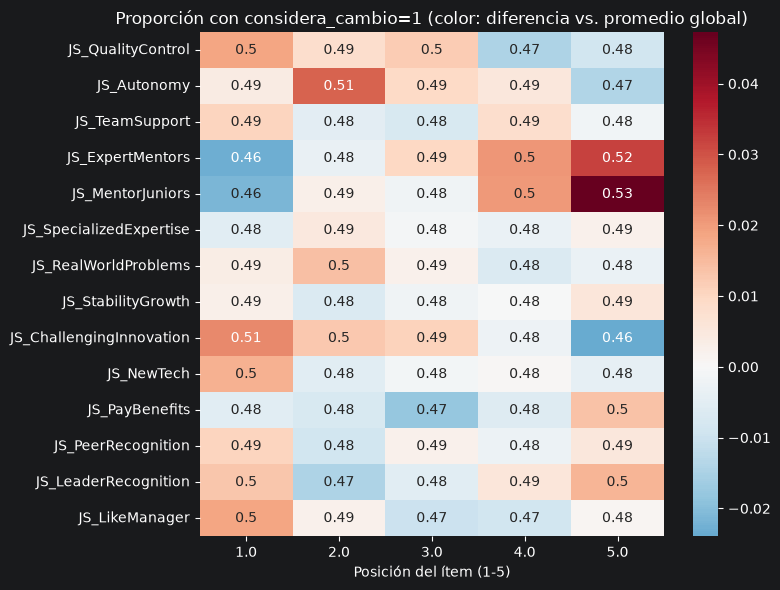

In [169]:
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
from statsmodels.stats.multitest import multipletests

# Datos: si querés usar solo un subconjunto de filas, filtralo acá
df = Stack_apartadas.dropna(subset=cols_js + ["considera_cambio"])
y = df["considera_cambio"].astype(int)

# 1) Chi-cuadrado por ítem + V de Cramér + corrección de Holm
res = []
for v in cols_js:
    tab = pd.crosstab(df[v], y)
    chi2, p, _, _ = chi2_contingency(tab)
    res.append((v, chi2, p, association(tab, method="cramer")))

res = pd.DataFrame(res, columns=["variable", "chi2", "p", "V_Cramer"])
res["p_Holm"] = multipletests(res["p"], method="holm")[1]
print(res.sort_values("p").round(4))

# 2) Heatmap: proporción de considera_cambio=1 según posición del ítem
prop = pd.DataFrame({v: y.groupby(df[v]).mean() for v in cols_js}).T
plt.figure(figsize=(8, 6))
sns.heatmap(prop - y.mean(), annot=prop.round(2), fmt="", cmap="RdBu_r", center=0)
plt.xlabel("Posición del ítem (1-5)")
plt.title("Proporción con considera_cambio=1 (color: diferencia vs. promedio global)")
plt.tight_layout()
plt.show()

Con esto vamos a probar sacando algunas de las variables de abajo, esto reduce la multicolinealidad y quiza nos permite armar grupos

In [170]:
cols_js= [
    "JS_QualityControl", "JS_Autonomy", "JS_TeamSupport", "JS_ExpertMentors",
    "JS_MentorJuniors", "JS_RealWorldProblems",
    "JS_StabilityGrowth", "JS_ChallengingInnovation", "JS_NewTech",
    "JS_PayBenefits", "JS_PeerRecognition", "JS_LeaderRecognition", "JS_LikeManager",
]

Calculamos un PCA para ver si tiene sentido graficarlo

In [171]:
X = Stack_apartadas[cols_js].dropna()
pca = PCA().fit(X)
tabla = pd.DataFrame({
    "Componente": [f"PC{i+1}" for i in range(len(cols_js))],
    "Var. explicada (%)": (pca.explained_variance_ratio_ * 100).round(2),
    "Acumulada (%)": (np.cumsum(pca.explained_variance_ratio_) * 100).round(2),
})
tabla

,Componente,Var. explicada (%),Acumulada (%)
0,PC1,13.42,13.42
1,PC2,10.79,24.21
2,PC3,10.06,34.27
3,PC4,9.47,43.75
4,PC5,8.15,51.89
5,PC6,7.96,59.85
6,PC7,7.48,67.34
7,PC8,7.20,74.54
8,PC9,6.69,81.23
9,PC10,6.63,87.86


Como vemos para juntar el 70% de la variabilidad necesitamos 8 variables y con 5 no conseguimos ni un 50%

Vamos a hacer un clustering con k-modes en lugar de k-means, porque las variables son muy discretas para tomar las medias (ademas k-means fue intentado sin ningun exito en la busqueda de clusters que expliquen la hipotesis)

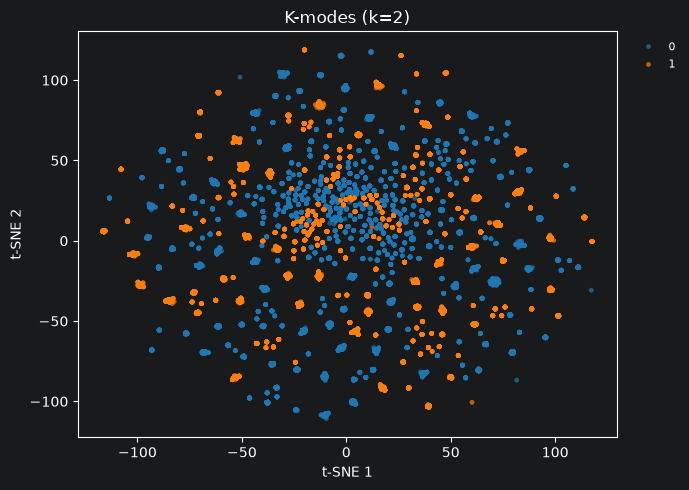

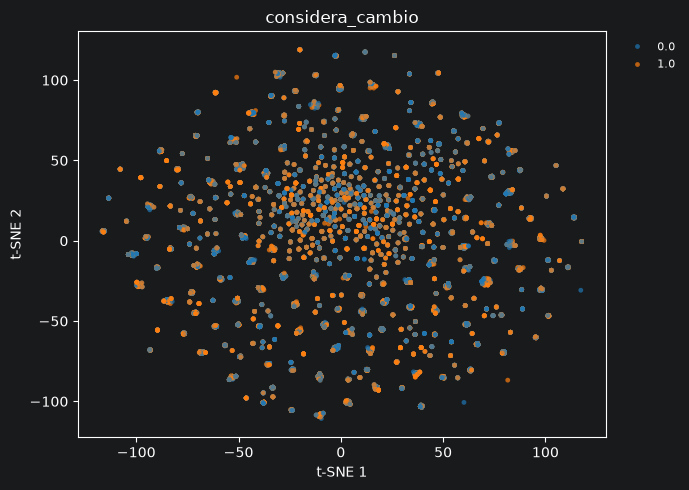

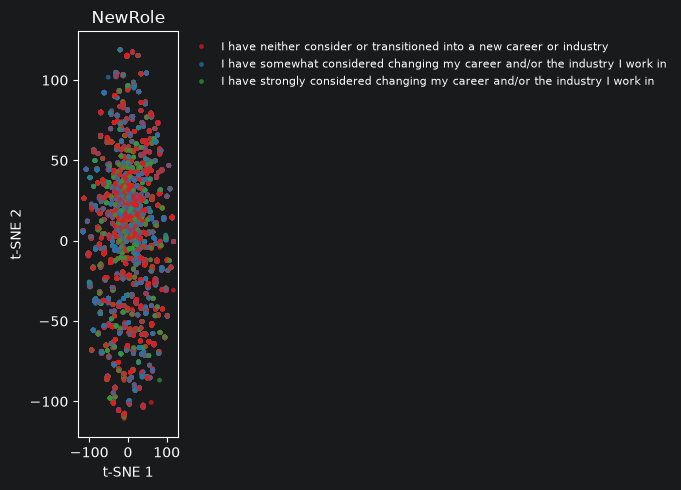

In [177]:
from kmodes.kmodes import KModes
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = Stack_apartadas[cols_js + ["considera_cambio", "NewRole"]].dropna()
X = df[cols_js]

clusters = KModes(n_clusters=2, init="Huang", n_init=10, random_state=0).fit_predict(X)

# t-SNE con distancia de Hamming (se calcula UNA vez y se reutiliza)
emb = TSNE(metric="hamming", init="random", random_state=0).fit_transform(X.astype(int))

# Rojo, azul y verde, todos con intensidad similar
cats = df["NewRole"].unique()
colores = ["#E41A1C", "#1F77B4", "#2CA02C"]
pal_role = dict(zip(cats, colores))


def plot_tsne(emb, valores, titulo, palette="tab10", figsize=(7, 5)):
    fig, ax = plt.subplots(figsize=figsize)
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=np.asarray(valores),
                    palette=palette, s=12, alpha=0.7, linewidth=0, ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8, frameon=False)
    plt.tight_layout()
    plt.show()


plot_tsne(emb, clusters, "K-modes (k=2)")

plot_tsne(emb, df["considera_cambio"], "considera_cambio")

plot_tsne(emb, df["NewRole"], "NewRole", palette=pal_role)

El grafico muestra como se distrubuyen los clusters, el siguiente como las muestras se reparten segun si considera o no un cambio y el tercero como se reparten pero en la categoria de newRole

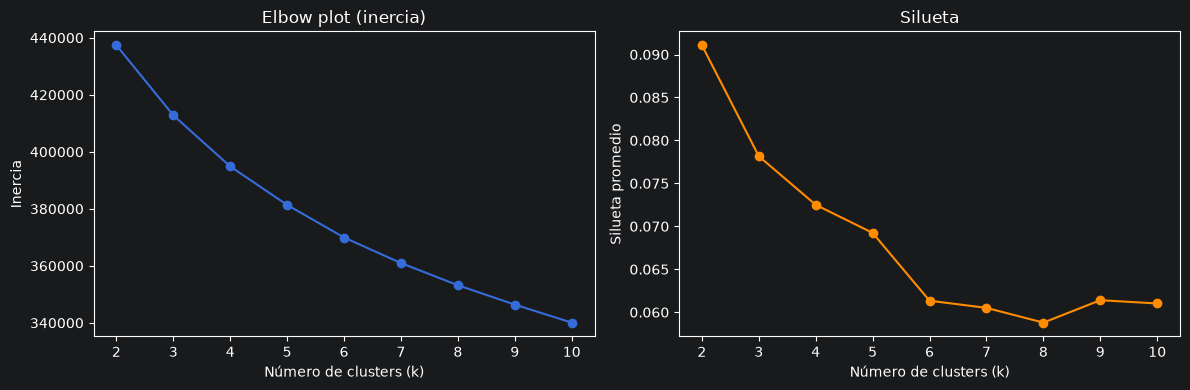

In [173]:
X = Stack_apartadas[cols_js].dropna().to_numpy(dtype=float)
ks = range(2, 11)
inercia, sil = [], []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=10).fit(X)
    inercia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_, random_state=10))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inercia, "o-")
ax[0].set(title="Elbow plot (inercia)", xlabel="Número de clusters (k)", ylabel="Inercia")
ax[1].plot(ks, sil, "o-", color="darkorange")
ax[1].set(title="Silueta", xlabel="Número de clusters (k)", ylabel="Silueta promedio")
plt.tight_layout()
plt.show()

In [174]:
print(pd.crosstab(clusters, y, normalize="index").round(3))

considera_cambio      0      1
row_0                         
0                 0.515  0.485
1                 0.518  0.482


Tras múltiples pruebas con distintos valores de k, el coeficiente de silueta nunca alcanzó valores satisfactorios y el método del codo no mostró un punto de inflexión claro, lo que sugiere que las respuestas a los ítems JS no presentan una estructura de grupos bien definida. Por lo tanto, nos apoyamos en los tests de chi-cuadrado y en el heatmap de proporciones, que indican que algunos ítems podrían asociarse de forma muy leve con la decisión de cambiar de rol. Con esta información, repetimos el clustering utilizando solo los ítems con mayor asociación, entendiendo que esta selección se hizo en función del desenlace y que el análisis es meramente exploratorio.

In [175]:
cols_js= [ "JS_Autonomy","JS_ExpertMentors",
    "JS_MentorJuniors", "JS_ChallengingInnovation"
]

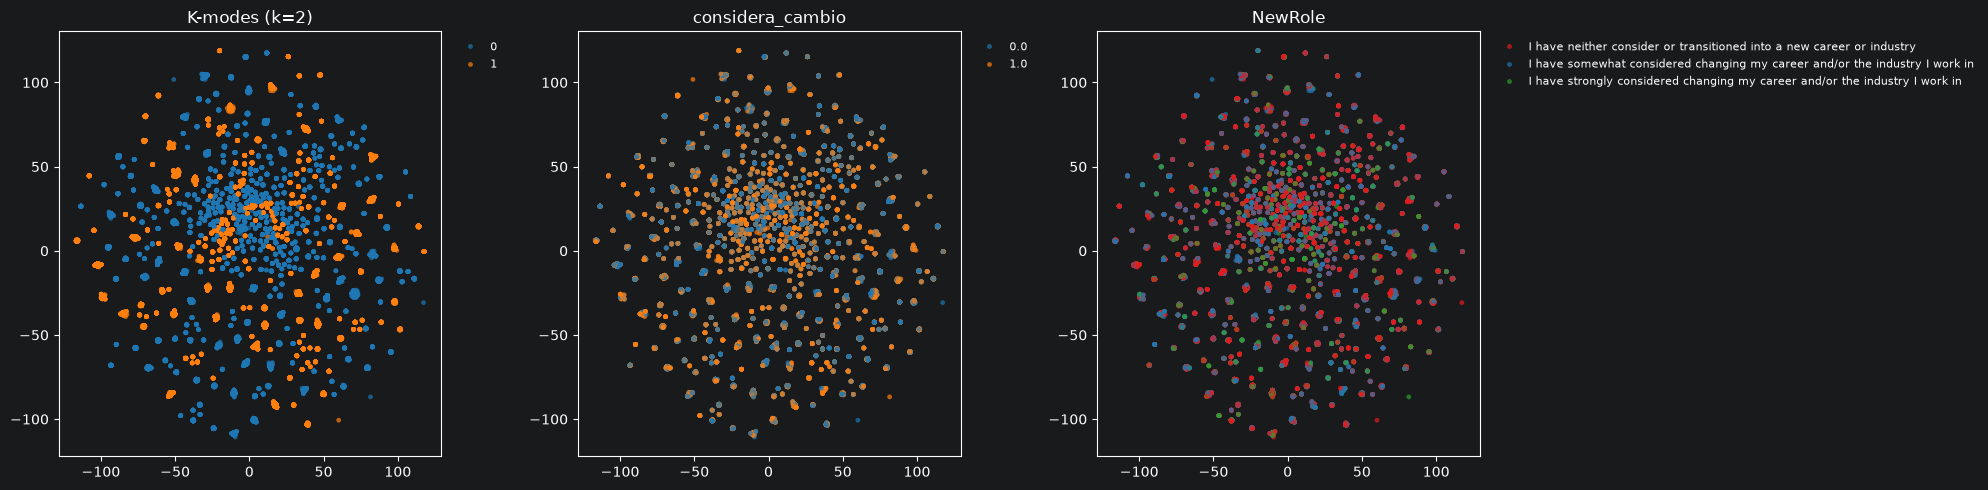

In [176]:
from kmodes.kmodes import KModes
from sklearn.manifold import TSNE

df = Stack_apartadas[cols_js + ["considera_cambio", "NewRole"]].dropna()
X = df[cols_js]

clusters = KModes(n_clusters=2, init="Huang", n_init=10, random_state=0).fit_predict(X)

# t-SNE con distancia de Hamming (apropiada para categóricas)
emb = TSNE(metric="hamming", init="random", random_state=0).fit_transform(X.astype(int))

# Rojo, azul y verde, todos con intensidad similar
cats = df["NewRole"].unique()
colores = ["#E41A1C", "#1F77B4", "#2CA02C"]
pal_role = dict(zip(cats, colores))

paneles = [(clusters, "K-modes (k=2)", "tab10"),
           (df["considera_cambio"], "considera_cambio", "tab10"),
           (df["NewRole"], "NewRole", pal_role)]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, (v, titulo, pal) in zip(axes, paneles):
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=np.asarray(v), palette=pal,
                    s=12, alpha=0.7, linewidth=0, ax=ax)
    ax.set_title(titulo)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

Aun reduciendo las variables a las que mostraron mayor asociación individual con considera_cambio, los grupos obtenidos no se diferencian en la proporción de personas que consideran cambiar (diferencias de pocos puntos porcentuales). Esto es coherente con los tamaños de efecto muy pequeños observados en los tests por ítem. En conjunto, los ítems JS no parecen discriminar la intención de cambio de forma relevante, por lo que no se justifica profundizar en esta línea con este conjunto de variables.